# IMDb Movie Review Sentiment Analysis

## Objective
Compare two approaches for classifying movie reviews as positive or negative:

1. TF-IDF with a Linear SVM.
2. Pretrained word embeddings with a CNN.

## First step
Inspect the dataset before preprocessing and training.

In [1]:
from pathlib import Path

# List CSV files attached to this notebook.
csv_files = list(Path("/kaggle/input").rglob("*.csv"))

for path in csv_files:
    print(path)

/kaggle/input/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews/IMDB Dataset.csv


In [2]:
import pandas as pd

# Locate the IMDb dataset.
imdb_files = [
    path for path in csv_files
    if path.name == "IMDB Dataset.csv"
]

if len(imdb_files) != 1:
    raise ValueError(
        "Expected one IMDB Dataset.csv file. "
        "Check that the correct dataset is attached."
    )

# Load the CSV file into a table.
df = pd.read_csv(imdb_files[0])

# Display the first five rows.
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [3]:
# Check the dataset size.
print("Rows and columns:", df.shape)

# Count reviews in each sentiment class.
print("\nSentiment counts:")
print(df["sentiment"].value_counts(dropna=False))

# Count missing values in each column.
print("\nMissing values:")
print(df.isna().sum())

# Count repeated review texts.
print("\nDuplicate reviews:")
print(df.duplicated(subset=["review"]).sum())

# Count reviews containing only whitespace or an empty string.
empty_reviews = df["review"].fillna("").str.strip().eq("")
print("\nEmpty or blank reviews:")
print(empty_reviews.sum())

Rows and columns: (50000, 2)

Sentiment counts:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Missing values:
review       0
sentiment    0
dtype: int64

Duplicate reviews:
418

Empty or blank reviews:
0


In [4]:
# Count distinct labels for each review text.
labels_per_review = df.groupby("review")["sentiment"].nunique()

# Find identical reviews with conflicting labels.
conflicting_reviews = labels_per_review[labels_per_review > 1]

print("Review texts with conflicting labels:", len(conflicting_reviews))

Review texts with conflicting labels: 0


In [5]:
# Keep one copy of each review and reset row numbering.
df_clean = (
    df.drop_duplicates(subset=["review"])
    .reset_index(drop=True)
    .copy()
)

print("Original reviews:", len(df))
print("Unique reviews:", len(df_clean))
print("Removed duplicates:", len(df) - len(df_clean))

print("\nSentiment counts after removing duplicates:")
print(df_clean["sentiment"].value_counts())

Original reviews: 50000
Unique reviews: 49582
Removed duplicates: 418

Sentiment counts after removing duplicates:
sentiment
positive    24884
negative    24698
Name: count, dtype: int64


In [6]:
# Estimate review length using whitespace-separated words.
df_clean["word_count"] = df_clean["review"].str.split().str.len()

print("Review length statistics:")
print(
    df_clean["word_count"].describe(
        percentiles=[0.5, 0.9, 0.95]
    ).round(1)
)

# Compare review lengths across sentiment classes.
print("\nReview lengths by sentiment:")
print(
    df_clean.groupby("sentiment")["word_count"]
    .agg(["mean", "median", "max"])
    .round(1)
)

Review length statistics:
count    49582.0
mean       231.4
std        171.5
min          4.0
50%        173.0
90%        452.0
95%        591.0
max       2470.0
Name: word_count, dtype: float64

Review lengths by sentiment:
            mean  median   max
sentiment                     
negative   229.6   174.0  1522
positive   233.1   172.0  2470


In [7]:
import html
import re

def clean_text(text):
    # Convert HTML entities, such as &amp;, into readable characters.
    text = html.unescape(text)

    # Replace HTML tags with spaces.
    text = re.sub(r"<[^>]+>", " ", text)

    # Convert text to lowercase.
    text = text.lower()

    # Replace repeated whitespace with one space.
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [8]:
example = "The movie was <br /> NOT good &amp; very boring!"

print("Before:", example)
print("After: ", clean_text(example))

Before: The movie was <br /> NOT good &amp; very boring!
After:  the movie was not good & very boring!


In [9]:
# Clean each review and store the result in a new column.
df_clean["review_clean"] = df_clean["review"].apply(clean_text)

# Display one review before and after cleaning.
print("ORIGINAL:\n", df_clean.loc[0, "review"])
print("\nCLEANED:\n", df_clean.loc[0, "review_clean"])

ORIGINAL:
 One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show is due

In [10]:
# Check whether cleaning produced empty texts.
blank_after_cleaning = df_clean["review_clean"].eq("").sum()

# Count repeated texts after cleaning.
duplicates_after_cleaning = df_clean.duplicated(
    subset=["review_clean"]
).sum()

# Check whether identical cleaned texts have different labels.
labels_per_clean_review = (
    df_clean.groupby("review_clean")["sentiment"].nunique()
)
conflicts_after_cleaning = (labels_per_clean_review > 1).sum()

print("Blank reviews after cleaning:", blank_after_cleaning)
print("Duplicate reviews after cleaning:", duplicates_after_cleaning)
print("Texts with conflicting labels:", conflicts_after_cleaning)

Blank reviews after cleaning: 0
Duplicate reviews after cleaning: 4
Texts with conflicting labels: 0


In [11]:
# Keep one copy of each cleaned review.
df_ready = (
    df_clean.drop_duplicates(subset=["review_clean"])
    .reset_index(drop=True)
    .copy()
)

print("Reviews ready for splitting:", len(df_ready))

Reviews ready for splitting: 49578


In [12]:
from sklearn.model_selection import train_test_split

# Reserve 20% for validation and testing.
train_df, remaining_df = train_test_split(
    df_ready,
    test_size=0.20,
    stratify=df_ready["sentiment"],
    random_state=42
)

# Divide the reserved portion equally.
val_df, test_df = train_test_split(
    remaining_df,
    test_size=0.50,
    stratify=remaining_df["sentiment"],
    random_state=42
)

for name, subset in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name}: {len(subset)} reviews")
    print(subset["sentiment"].value_counts())


Training: 39662 reviews
sentiment
positive    19905
negative    19757
Name: count, dtype: int64

Validation: 4958 reviews
sentiment
positive    2489
negative    2469
Name: count, dtype: int64

Test: 4958 reviews
sentiment
positive    2488
negative    2470
Name: count, dtype: int64


In [13]:
# Define the numeric label for each sentiment.
label_mapping = {"negative": 0, "positive": 1}

# Prepare training inputs and labels.
X_train = train_df["review_clean"].copy()
y_train = train_df["sentiment"].map(label_mapping)

# Prepare validation inputs and labels.
X_val = val_df["review_clean"].copy()
y_val = val_df["sentiment"].map(label_mapping)

# Prepare test inputs and labels.
X_test = test_df["review_clean"].copy()
y_test = test_df["sentiment"].map(label_mapping)

# Display one training example.
print("Training review:\n", X_train.iloc[0])
print("\nTraining label:", y_train.iloc[0])

Training review:
 i saw this film on tv many years ago and i saw this film when i got this on tape. i thought that this was reasonably well done. it was not the best of all movies, but it was good enough. the movie has enough talent to inspire many people, especially younger kids. the acting was good, with danny glover leading the cast. the plot line was not very believable, but the script was well written. this movie can also be the interest of avid baseball fans. it does not directly apply to a action-packed sports movie. it directly applies to a nice film that you can watch with your family and learn some messages that are hidden in this film. overall, the film was good, but not great. i give this a movie a 7/10.

Training label: 1


In [14]:
import re

def tokenize_text(text):
    # Extract words while preserving internal apostrophes.
    return re.findall(r"[a-z]+(?:'[a-z]+)?", text)

# Tokenize one training review.
example_tokens = tokenize_text(X_train.iloc[0])

print("First 40 tokens:")
print(example_tokens[:40])

print("\nNumber of tokens:", len(example_tokens))

First 40 tokens:
['i', 'saw', 'this', 'film', 'on', 'tv', 'many', 'years', 'ago', 'and', 'i', 'saw', 'this', 'film', 'when', 'i', 'got', 'this', 'on', 'tape', 'i', 'thought', 'that', 'this', 'was', 'reasonably', 'well', 'done', 'it', 'was', 'not', 'the', 'best', 'of', 'all', 'movies', 'but', 'it', 'was', 'good']

Number of tokens: 136


In [15]:
def normalize_negation(text):
    # Normalize curly apostrophes.
    text = text.replace("’", "'")

    # Handle contractions with irregular forms.
    text = re.sub(r"\bcan't\b", "can not", text)
    text = re.sub(r"\bwon't\b", "will not", text)
    text = re.sub(r"\bshan't\b", "shall not", text)
    text = re.sub(r"\bcannot\b", "can not", text)

    # Expand regular negative contractions.
    text = re.sub(r"n't\b", " not", text)

    return text

In [16]:
example = "I didn't enjoy this movie. I can't recommend it."

# Clean text, normalize negation, then extract tokens.
cleaned = clean_text(example)
normalized = normalize_negation(cleaned)
tokens = tokenize_text(normalized)

print("Normalized:", normalized)
print("Tokens:", tokens)

Normalized: i did not enjoy this movie. i can not recommend it.
Tokens: ['i', 'did', 'not', 'enjoy', 'this', 'movie', 'i', 'can', 'not', 'recommend', 'it']


In [17]:
import nltk
from nltk import pos_tag
from nltk.stem import WordNetLemmatizer

# Download the linguistic resources.
nltk.download("wordnet")
nltk.download("averaged_perceptron_tagger_eng")

# Create the lemmatizer.
lemmatizer = WordNetLemmatizer()

[nltk_data] Downloading package wordnet to /usr/share/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /usr/share/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.


In [18]:
def lemmatize_tokens(tokens):
    # Identify each word's grammatical role.
    tagged_tokens = pos_tag(tokens)

    # Convert tag initials to WordNet's expected format.
    pos_mapping = {
        "J": "a",  # Adjective
        "V": "v",  # Verb
        "N": "n",  # Noun
        "R": "r"   # Adverb
    }

    lemmas = []

    for word, tag in tagged_tokens:
        wordnet_pos = pos_mapping.get(tag[0])

        if wordnet_pos is not None:
            lemma = lemmatizer.lemmatize(word, pos=wordnet_pos)
        else:
            lemma = word

        lemmas.append(lemma)

    return lemmas

In [19]:
example = "The actors were watching movies, but I didn't enjoy them."

cleaned = clean_text(example)
normalized = normalize_negation(cleaned)
tokens = tokenize_text(normalized)
lemmas = lemmatize_tokens(tokens)

print("Tokens:", tokens)
print("Lemmas:", lemmas)

Tokens: ['the', 'actors', 'were', 'watching', 'movies', 'but', 'i', 'did', 'not', 'enjoy', 'them']
Lemmas: ['the', 'actor', 'be', 'watch', 'movie', 'but', 'i', 'do', 'not', 'enjoy', 'them']


In [20]:
def preprocess_review(cleaned_text):
    # Normalize negative contractions.
    normalized = normalize_negation(cleaned_text)

    # Split the text into tokens.
    tokens = tokenize_text(normalized)

    # Convert tokens to their base forms.
    lemmas = lemmatize_tokens(tokens)

    # Join the tokens into one string.
    return " ".join(lemmas)

In [21]:
example = "the actors were watching movies, but i didn't enjoy them."

print("Before:", example)
print("After: ", preprocess_review(example))

Before: the actors were watching movies, but i didn't enjoy them.
After:  the actor be watch movie but i do not enjoy them


In [22]:
from tqdm.auto import tqdm

# Enable progress bars for pandas operations.
tqdm.pandas(desc="Preprocessing")

# Process each split independently.
X_train_processed = X_train.progress_apply(preprocess_review)
X_val_processed = X_val.progress_apply(preprocess_review)
X_test_processed = X_test.progress_apply(preprocess_review)

# Check for texts that became empty.
for name, texts in [
    ("Training", X_train_processed),
    ("Validation", X_val_processed),
    ("Test", X_test_processed)
]:
    print(f"{name}: {len(texts)} reviews, {texts.eq('').sum()} empty")

Preprocessing:   0%|          | 0/39662 [00:00<?, ?it/s]

Preprocessing:   0%|          | 0/4958 [00:00<?, ?it/s]

Preprocessing:   0%|          | 0/4958 [00:00<?, ?it/s]

Training: 39662 reviews, 0 empty
Validation: 4958 reviews, 0 empty
Test: 4958 reviews, 0 empty


In [23]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Define how reviews will be converted into numeric features.
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=50000,
    min_df=2,
    tokenizer=str.split,
    token_pattern=None,
    lowercase=False
)

# Learn the vocabulary and IDF weights from training data only.
X_train_tfidf = tfidf.fit_transform(X_train_processed)

# Reuse the learned representation for validation and test data.
X_val_tfidf = tfidf.transform(X_val_processed)
X_test_tfidf = tfidf.transform(X_test_processed)

print("Training matrix:", X_train_tfidf.shape)
print("Validation matrix:", X_val_tfidf.shape)
print("Test matrix:", X_test_tfidf.shape)

Training matrix: (39662, 50000)
Validation matrix: (4958, 50000)
Test matrix: (4958, 50000)


In [24]:
from sklearn.svm import LinearSVC
from time import perf_counter

# Create the classifier.
svm_model = LinearSVC(
    C=1.0,
    max_iter=5000,
    random_state=42
)

# Train using training data only.
start = perf_counter()

svm_model.fit(X_train_tfidf, y_train)

training_seconds = perf_counter() - start

print(f"Training completed in {training_seconds:.1f} seconds.")

Training completed in 1.1 seconds.


In [25]:
from sklearn.metrics import classification_report, roc_auc_score

# Predict sentiment labels.
val_predictions = svm_model.predict(X_val_tfidf)

# Obtain scores for ROC-AUC.
val_scores = svm_model.decision_function(X_val_tfidf)

print("Validation results:")
print(
    classification_report(
        y_val,
        val_predictions,
        labels=[0, 1],
        target_names=["Negative", "Positive"],
        digits=4
    )
)

print(f"Validation ROC-AUC: {roc_auc_score(y_val, val_scores):.4f}")

Validation results:
              precision    recall  f1-score   support

    Negative     0.9072    0.9068    0.9070      2469
    Positive     0.9076    0.9080    0.9078      2489

    accuracy                         0.9074      4958
   macro avg     0.9074    0.9074    0.9074      4958
weighted avg     0.9074    0.9074    0.9074      4958

Validation ROC-AUC: 0.9685


In [26]:
from sklearn.metrics import confusion_matrix

# Count predictions for each actual/predicted label combination.
cm = confusion_matrix(
    y_val,
    val_predictions,
    labels=[0, 1]
)

# Give the matrix readable row and column names.
cm_table = pd.DataFrame(
    cm,
    index=["Actual Negative", "Actual Positive"],
    columns=["Predicted Negative", "Predicted Positive"]
)

display(cm_table)

,Predicted Negative,Predicted Positive
Actual Negative,2239,230
Actual Positive,229,2260


In [27]:
# Keep the original reviews and their true sentiment labels.
validation_results = (
    val_df[["review", "sentiment"]]
    .reset_index(drop=True)
    .copy()
)

# Add readable model predictions.
validation_results["predicted"] = pd.Series(
    val_predictions
).map({0: "negative", 1: "positive"})

# Keep only incorrect predictions.
errors = validation_results[
    validation_results["sentiment"]
    != validation_results["predicted"]
].copy()

print("Number of errors:", len(errors))

# Display the first incorrect prediction.
first_error = errors.iloc[0]

print("\nReview:\n", first_error["review"])
print("\nActual sentiment:", first_error["sentiment"])
print("Predicted sentiment:", first_error["predicted"])

Number of errors: 459

Review:
 Growing up with the Beast Wars transformers, I wasn't very familiar with the original Transformers, and now that I have seen the awesome movie, and now that I have seen the older cartoon on which it's based, I have to say I like the original cartoon and the live action movie more than Beast Wars.<br /><br />Not that I don't like the BW characters, I just think that characters like Optimus Prime are better than Optimus Primal.<br /><br />I mean, "AUTOBOTS TRANSFORM AND ROLL OUT!" sounds a lot better than "MAXIMALS MAXIMIZE!" The voice of the original Optimus Prime still makes me a strong believer that he's a real commander, more so than Optimus Primal.<br /><br />Besides, Powermaster Optimus Prime is a lot more powerful than Optimal Optimus. Just look on the web! <br /><br />Megatron in the BW character seemed more like a humorous version of the more evil version of him in the original series.<br /><br />Besides what's cooler, robots changing into animals

In [28]:
# Create a table linking features to their learned weights.
feature_weights = pd.DataFrame({
    "feature": tfidf.get_feature_names_out(),
    "weight": svm_model.coef_[0]
})

print("Strongest positive weights:")
display(feature_weights.nlargest(10, "weight"))

print("Strongest negative weights:")
display(feature_weights.nsmallest(10, "weight"))

Strongest positive weights:


,feature,weight
14809,excellent,3.419705
32203,perfect,3.263568
18289,great,3.227969
19977,hilarious,2.626106
14153,enjoyable,2.566977
750,a must,2.526230
45319,today,2.472688
17189,fun,2.274623
2858,amazing,2.272484
8350,brilliant,2.271305


Strongest negative weights:


,feature,weight
5564,awful,-4.603974
5686,bad,-4.577175
8122,boring,-3.720087
29099,not recommend,-3.526990
47407,waste,-3.475173
32906,poor,-3.412185
40892,the bad,-3.391561
12758,disappointment,-3.314088
20640,horrible,-3.168717
16815,forgettable,-3.064804


In [29]:
from pathlib import Path
import joblib

# Create an output folder.
output_dir = Path("/kaggle/working/sentiment_project")
output_dir.mkdir(parents=True, exist_ok=True)

# Save the fitted vectorizer and trained classifier.
joblib.dump(tfidf, output_dir / "tfidf_vectorizer.joblib")
joblib.dump(svm_model, output_dir / "svm_model.joblib")

# Save each split with its original and processed text.
for name, split_df, processed_text in [
    ("train", train_df, X_train_processed),
    ("validation", val_df, X_val_processed),
    ("test", test_df, X_test_processed)
]:
    saved_df = split_df[["review", "sentiment"]].reset_index(drop=True).copy()
    saved_df["processed_review"] = processed_text.to_numpy()

    saved_df.to_csv(output_dir / f"{name}.csv", index=False)

# Save validation predictions and feature weights.
validation_results.to_csv(
    output_dir / "svm_validation_predictions.csv", index=False
)
feature_weights.to_csv(
    output_dir / "svm_feature_weights.csv", index=False
)

print("Files saved in:", output_dir)

Files saved in: /kaggle/working/sentiment_project


In [30]:
import tensorflow as tf
from tensorflow.keras.layers import TextVectorization

# Set the random seed for reproducibility.
tf.keras.utils.set_random_seed(42)

# Estimate token lengths from training data only.
train_lengths = X_train_processed.str.split().str.len()

# Choose a length covering approximately 90% of training reviews.
sequence_length = int(train_lengths.quantile(0.90))

# Limit the vocabulary size to control memory and computation.
max_tokens = 20000

# Create the text-to-integer converter.
cnn_vectorizer = TextVectorization(
    max_tokens=max_tokens,
    standardize=None,
    split="whitespace",
    output_mode="int",
    output_sequence_length=sequence_length
)

# Learn the vocabulary from training text only.
training_text_dataset = tf.data.Dataset.from_tensor_slices(
    X_train_processed.to_numpy()
).batch(256)

cnn_vectorizer.adapt(training_text_dataset)

print("Sequence length:", sequence_length)
print("Vocabulary size:", len(cnn_vectorizer.get_vocabulary()))

# Inspect the integer representation of one review.
example_ids = cnn_vectorizer(
    tf.constant([X_train_processed.iloc[0]])
)

print("First 20 token IDs:", example_ids.numpy()[0, :20])
print("Example shape:", example_ids.shape)

I0000 00:00:1792887170.990501      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792887170.994351      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Sequence length: 450
Vocabulary size: 20000
First 20 token IDs: [  10  214   11   16   22  240  113  115  596    4   10  214   11   16
   52   10   40   11   22 1535]
Example shape: (1, 450)


In [31]:
from pathlib import Path

# Locate the attached pretrained embeddings file.
glove_files = list(
    Path("/kaggle/input").rglob("glove.6B.100d.txt")
)

if len(glove_files) != 1:
    raise FileNotFoundError(
        "Expected exactly one glove.6B.100d.txt file. "
        "Check the attached datasets."
    )

glove_path = glove_files[0]

print("Embeddings file:", glove_path)

# Inspect the first word and its vector size.
with glove_path.open("r", encoding="utf-8") as file:
    parts = file.readline().split()

print("Example word:", parts[0])
print("Vector dimensions:", len(parts) - 1)
print("First five values:", parts[1:6])

Embeddings file: /kaggle/input/datasets/danielwillgeorge/glove6b100dtxt/glove.6B.100d.txt
Example word: the
Vector dimensions: 100
First five values: ['-0.038194', '-0.24487', '0.72812', '-0.39961', '0.083172']


In [32]:
import numpy as np

# Get words in the same order as their token IDs.
vocabulary = cnn_vectorizer.get_vocabulary()
vocab_size = len(vocabulary)
embedding_dim = 100

# Initialize small random vectors for words not found in GloVe.
rng = np.random.default_rng(42)
embedding_matrix = rng.normal(
    loc=0.0,
    scale=0.05,
    size=(vocab_size, embedding_dim)
).astype("float32")

# Keep the padding vector equal to zero.
embedding_matrix[0] = 0.0

# Map vocabulary words to their IDs, excluding special tokens.
word_to_id = {
    word: index
    for index, word in enumerate(vocabulary)
    if index >= 2
}

found = 0

# Read the file line by line and keep only matching words.
with glove_path.open("r", encoding="utf-8") as file:
    for line in file:
        word, _, values = line.partition(" ")
        word_id = word_to_id.get(word)

        if word_id is not None:
            vector = np.fromstring(values, sep=" ", dtype="float32")

            if vector.size != embedding_dim:
                raise ValueError(f"Unexpected vector size for: {word}")

            embedding_matrix[word_id] = vector
            found += 1

coverage = found / len(word_to_id)

print("Embedding matrix shape:", embedding_matrix.shape)
print("Vocabulary words found in GloVe:", found)
print("Vocabulary words not found:", len(word_to_id) - found)
print(f"Vocabulary coverage: {coverage:.2%}")

Embedding matrix shape: (20000, 100)
Vocabulary words found in GloVe: 18938
Vocabulary words not found: 1060
Vocabulary coverage: 94.70%


In [33]:
from tensorflow.keras import layers

# Build a CNN using pretrained word embeddings.
cnn_model = tf.keras.Sequential([
    layers.Input(shape=(sequence_length,), dtype="int32"),

    layers.Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        embeddings_initializer=tf.keras.initializers.Constant(
            embedding_matrix
        ),
        trainable=False
    ),

    layers.Conv1D(
        filters=128,
        kernel_size=5,
        activation="relu"
    ),

    layers.GlobalMaxPooling1D(),

    layers.Dense(64, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(1, activation="sigmoid")
])

# Configure the training procedure.
cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 450, 100)       │     2,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 446, 128)       │        64,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 128)            │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,072,449 (7.91 MB)

 Trainable params: 72,449 (283.00 KB)

 Non-trainable params: 2,000,000 (7.63 MB)

In [34]:
# Convert text into fixed-length integer sequences.
X_train_cnn = cnn_vectorizer(
    tf.constant(X_train_processed.to_numpy())
).numpy().astype("int32")

X_val_cnn = cnn_vectorizer(
    tf.constant(X_val_processed.to_numpy())
).numpy().astype("int32")

print("Training inputs:", X_train_cnn.shape)
print("Validation inputs:", X_val_cnn.shape)

Training inputs: (39662, 450)
Validation inputs: (4958, 450)


In [35]:
from pathlib import Path
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

checkpoint_dir = Path("/kaggle/working/sentiment_project")
checkpoint_dir.mkdir(parents=True, exist_ok=True)

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        filepath=str(checkpoint_dir / "best_cnn.keras"),
        monitor="val_loss",
        save_best_only=True
    )
]

In [36]:
from time import perf_counter

start = perf_counter()

cnn_history = cnn_model.fit(
    X_train_cnn,
    y_train.to_numpy(),
    validation_data=(X_val_cnn, y_val.to_numpy()),
    epochs=10,
    batch_size=64,
    shuffle=True,
    callbacks=callbacks,
    verbose=2
)

cnn_training_seconds = perf_counter() - start

print(f"\nTraining time: {cnn_training_seconds:.1f} seconds")

Epoch 1/10


I0000 00:00:1792887187.655731     140 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


620/620 - 15s - 25ms/step - accuracy: 0.7593 - auc: 0.8462 - loss: 0.4859 - val_accuracy: 0.8491 - val_auc: 0.9282 - val_loss: 0.3465
Epoch 2/10
620/620 - 8s - 12ms/step - accuracy: 0.8561 - auc: 0.9276 - loss: 0.3444 - val_accuracy: 0.8685 - val_auc: 0.9401 - val_loss: 0.3132
Epoch 3/10
620/620 - 4s - 6ms/step - accuracy: 0.8818 - auc: 0.9490 - loss: 0.2900 - val_accuracy: 0.8637 - val_auc: 0.9435 - val_loss: 0.3136
Epoch 4/10
620/620 - 7s - 12ms/step - accuracy: 0.9050 - auc: 0.9643 - loss: 0.2426 - val_accuracy: 0.8667 - val_auc: 0.9438 - val_loss: 0.3040
Epoch 5/10
620/620 - 4s - 6ms/step - accuracy: 0.9194 - auc: 0.9741 - loss: 0.2061 - val_accuracy: 0.8481 - val_auc: 0.9433 - val_loss: 0.3599
Epoch 6/10
620/620 - 3s - 5ms/step - accuracy: 0.9369 - auc: 0.9824 - loss: 0.1686 - val_accuracy: 0.8578 - val_auc: 0.9411 - val_loss: 0.3572

Training time: 41.0 seconds


In [37]:
from sklearn.metrics import classification_report, roc_auc_score

# Get positive-sentiment scores from the restored best model.
cnn_val_scores = cnn_model.predict(
    X_val_cnn,
    batch_size=256,
    verbose=0
).ravel()

# Convert scores into labels using a fixed threshold.
cnn_val_predictions = (cnn_val_scores >= 0.5).astype("int32")

print("CNN validation results:")
print(
    classification_report(
        y_val,
        cnn_val_predictions,
        labels=[0, 1],
        target_names=["Negative", "Positive"],
        digits=4
    )
)

print(
    f"Validation ROC-AUC: "
    f"{roc_auc_score(y_val, cnn_val_scores):.4f}"
)

CNN validation results:
              precision    recall  f1-score   support

    Negative     0.8660    0.8663    0.8662      2469
    Positive     0.8674    0.8670    0.8672      2489

    accuracy                         0.8667      4958
   macro avg     0.8667    0.8667    0.8667      4958
weighted avg     0.8667    0.8667    0.8667      4958

Validation ROC-AUC: 0.9438


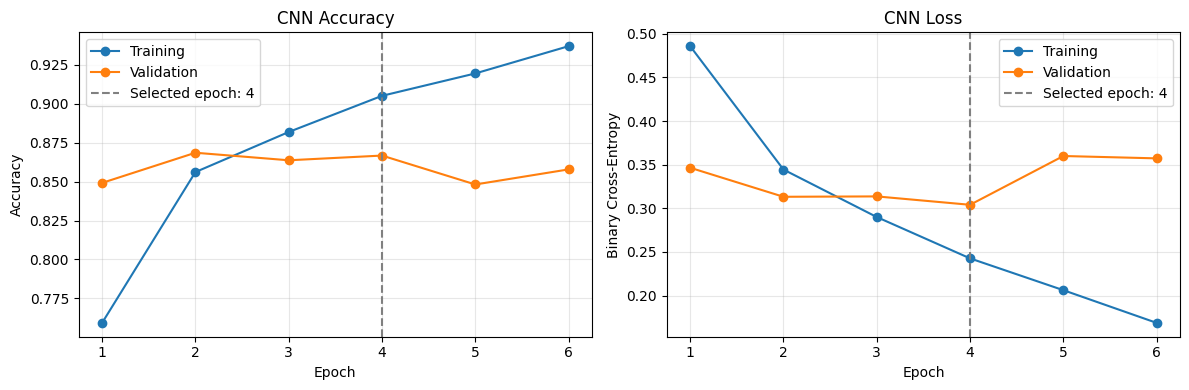

In [38]:
import matplotlib.pyplot as plt

# Retrieve the metrics recorded during training.
history = cnn_history.history
epochs = range(1, len(history["loss"]) + 1)

# Identify the epoch selected by minimum validation loss.
best_epoch = int(np.argmin(history["val_loss"])) + 1

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Plot training and validation accuracy.
axes[0].plot(epochs, history["accuracy"], marker="o", label="Training")
axes[0].plot(epochs, history["val_accuracy"], marker="o", label="Validation")
axes[0].set_title("CNN Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")

# Plot training and validation loss.
axes[1].plot(epochs, history["loss"], marker="o", label="Training")
axes[1].plot(epochs, history["val_loss"], marker="o", label="Validation")
axes[1].set_title("CNN Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Binary Cross-Entropy")

# Mark the selected epoch on both plots.
for ax in axes:
    ax.axvline(
        best_epoch,
        color="gray",
        linestyle="--",
        label=f"Selected epoch: {best_epoch}"
    )
    ax.set_xticks(list(epochs))
    ax.legend()
    ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(
    checkpoint_dir / "cnn_learning_curves.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

# Save the training history for the report.
history_table = pd.DataFrame(history)
history_table.index = range(1, len(history_table) + 1)
history_table.to_csv(
    checkpoint_dir / "cnn_training_history.csv",
    index_label="epoch"
)

In [39]:
# Predict test labels and scores with SVM.
svm_test_predictions = svm_model.predict(X_test_tfidf)
svm_test_scores = svm_model.decision_function(X_test_tfidf)

# Load the CNN checkpoint selected using validation loss.
cnn_model = tf.keras.models.load_model(
    str(checkpoint_dir / "best_cnn.keras")
)

# Convert test text using the existing training vocabulary.
X_test_cnn = cnn_vectorizer(
    tf.constant(X_test_processed.to_numpy())
).numpy().astype("int32")

# Predict positive-sentiment scores and labels.
cnn_test_scores = cnn_model.predict(
    X_test_cnn,
    batch_size=256,
    verbose=0
).ravel()

cnn_test_predictions = (cnn_test_scores >= 0.5).astype("int32")

In [40]:
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    roc_auc_score
)

test_rows = []
test_reports = {}

for name, predictions, scores in [
    ("TF-IDF + SVM", svm_test_predictions, svm_test_scores),
    ("GloVe + CNN", cnn_test_predictions, cnn_test_scores)
]:
    # Calculate per-class metrics and their averages.
    report = classification_report(
        y_test,
        predictions,
        labels=[0, 1],
        target_names=["Negative", "Positive"],
        output_dict=True,
        zero_division=0
    )

    test_reports[name] = report

    # Collect comparable summary metrics.
    test_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (macro)": report["macro avg"]["precision"],
        "Recall (macro)": report["macro avg"]["recall"],
        "F1 (macro)": report["macro avg"]["f1-score"],
        "ROC-AUC": roc_auc_score(y_test, scores)
    })

test_comparison = pd.DataFrame(test_rows)

display(test_comparison.round(4))

test_comparison.to_csv(
    checkpoint_dir / "test_model_comparison.csv",
    index=False
)

,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro),ROC-AUC
0,TF-IDF + SVM,0.9086,0.9089,0.9086,0.9086,0.9682
1,GloVe + CNN,0.8711,0.8711,0.8711,0.8711,0.9426


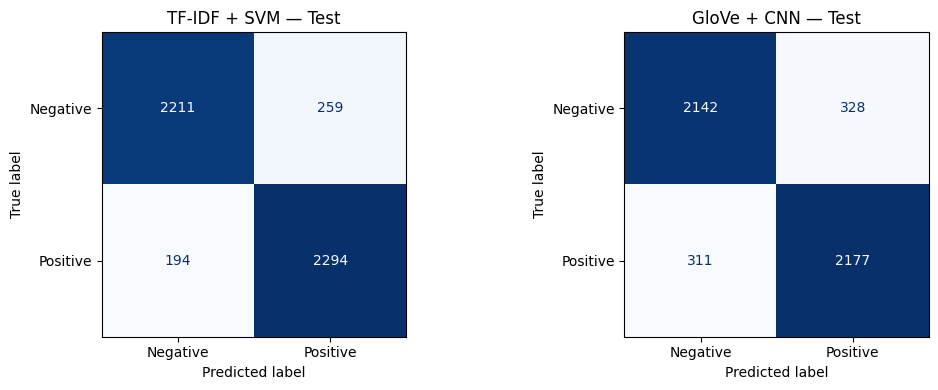

In [41]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, name, predictions in [
    (axes[0], "TF-IDF + SVM", svm_test_predictions),
    (axes[1], "GloVe + CNN", cnn_test_predictions)
]:
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=[0, 1],
        display_labels=["Negative", "Positive"],
        cmap="Blues",
        colorbar=False,
        values_format="d",
        ax=ax
    )

    ax.set_title(f"{name} — Test")

fig.tight_layout()
fig.savefig(
    checkpoint_dir / "test_confusion_matrices.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

In [42]:
def predict_sentiment(review):
    # Reject missing or blank input.
    if not isinstance(review, str) or not review.strip():
        raise ValueError("Please enter a non-empty English movie review.")

    # Apply the same preprocessing used during training.
    cleaned = clean_text(review)
    processed = preprocess_review(cleaned)

    if not processed:
        raise ValueError("The review contains no usable words.")

    # Predict with TF-IDF and SVM.
    svm_features = tfidf.transform([processed])
    svm_label = int(svm_model.predict(svm_features)[0])

    # Predict with the pretrained-embedding CNN.
    cnn_ids = cnn_vectorizer(tf.constant([processed]))
    cnn_score = float(cnn_model.predict(cnn_ids, verbose=0)[0, 0])
    cnn_label = int(cnn_score >= 0.5)

    # Convert numeric labels into readable results.
    label_names = {0: "Negative", 1: "Positive"}

    return {
        "TF-IDF + SVM": label_names[svm_label],
        "GloVe + CNN": label_names[cnn_label]
    }

In [43]:
review = "The film was decent, but I did not like the way it ended; I believe there should have been a different, more logical conclusion ."

results = predict_sentiment(review)

print("Review:", review)

for model_name, sentiment in results.items():
    print(f"{model_name}: {sentiment}")

Review: The film was decent, but I did not like the way it ended; I believe there should have been a different, more logical conclusion .
TF-IDF + SVM: Positive
GloVe + CNN: Negative


In [44]:
# Apply the same preprocessing to the demo review.
demo_processed = preprocess_review(clean_text(review))
demo_vector = tfidf.transform([demo_processed])

# Identify the features present in this review.
feature_ids = demo_vector.indices
feature_names = tfidf.get_feature_names_out()

# Calculate each feature's contribution to the SVM score.
contributions = pd.DataFrame({
    "feature": feature_names[feature_ids],
    "contribution": (
        demo_vector.data * svm_model.coef_[0, feature_ids]
    )
})

positive = contributions[contributions["contribution"] > 0]
negative = contributions[contributions["contribution"] < 0]

print("Processed review:", demo_processed)

print("\nStrongest positive contributions:")
display(positive.nlargest(5, "contribution"))

print("Strongest negative contributions:")
display(negative.nsmallest(5, "contribution"))

print("Bias:", float(svm_model.intercept_[0]))
print("SVM decision score:", float(
    svm_model.decision_function(demo_vector)[0]
))

Processed review: the film be decent but i do not like the way it end i believe there should have be a different more logical conclusion

Strongest positive contributions:


,feature,contribution
22,i believe,0.238179
12,different,0.177790
36,the way,0.149956
31,not like,0.141190
38,there should,0.093499


Strongest negative contributions:


,feature,contribution
1,a different,-0.198202
33,should have,-0.184026
25,it end,-0.133542
4,be decent,-0.107663
14,do not,-0.086682


Bias: -0.026985047908519244
SVM decision score: 0.1538233193908003


In [45]:
# Accept preprocessed text as input.
text_input = tf.keras.Input(
    shape=(),
    dtype=tf.string,
    name="preprocessed_review"
)

# Connect text vectorization to the trained CNN.
token_ids = cnn_vectorizer(text_input)
sentiment_score = cnn_model(token_ids)

cnn_text_model = tf.keras.Model(
    inputs=text_input,
    outputs=sentiment_score
)

# Save both components together.
cnn_text_model.save(
    checkpoint_dir / "cnn_with_vectorizer.keras"
)

print("Saved CNN together with its text vectorizer.")

Saved CNN together with its text vectorizer.


In [46]:
"""Copy this entire file into a final code cell in the trained Kaggle notebook."""

import importlib.metadata
import json
import platform
from pathlib import Path
import zipfile


def export_for_vscode(namespace):
    required = ("tfidf", "svm_model", "cnn_vectorizer", "clean_text", "preprocess_review")
    missing = [name for name in required if name not in namespace]
    if missing:
        raise RuntimeError(
            "Run this cell in the trained notebook. Missing: " + ", ".join(missing)
        )

    import joblib
    import tensorflow as tf

    source_dir = Path(namespace.get("checkpoint_dir", "/kaggle/working/sentiment_project"))
    best_checkpoint = source_dir / "best_cnn.keras"
    if not best_checkpoint.is_file():
        raise FileNotFoundError("The validation-selected best_cnn.keras checkpoint is missing.")

    # Reconstruct the text-input model from the selected checkpoint.
    # No model is trained or fitted here.
    best_cnn = tf.keras.models.load_model(best_checkpoint, compile=False)
    text_input = tf.keras.Input(shape=(), dtype=tf.string, name="preprocessed_review")
    output = best_cnn(namespace["cnn_vectorizer"](text_input))
    text_model = tf.keras.Model(text_input, output)

    export_dir = Path("/kaggle/working/vscode_models")
    export_dir.mkdir(parents=True, exist_ok=True)

    joblib.dump(namespace["tfidf"], export_dir / "tfidf_vectorizer.joblib")
    joblib.dump(namespace["svm_model"], export_dir / "svm_model.joblib")
    text_model.save(export_dir / "cnn_with_vectorizer.keras")

    package_names = ("scikit-learn", "numpy", "joblib", "nltk", "keras")
    packages = {name: importlib.metadata.version(name) for name in package_names}
    packages["tensorflow"] = tf.__version__

    metadata = {
        "python_version": platform.python_version(),
        "packages": packages,
        "cnn_threshold": 0.5,
        "cnn_selection": "minimum validation loss; best_cnn.keras",
        "preprocessing": "HTML cleaning, lowercase, negation expansion, regex tokens, POS-aware WordNet lemmatization",
        "labels": {"0": "Negative", "1": "Positive"},
    }
    (export_dir / "training_metadata.json").write_text(
        json.dumps(metadata, indent=2) + "\n", encoding="utf-8"
    )
    (export_dir / "requirements-inference.txt").write_text(
        "\n".join(f"{name}=={version}" for name, version in packages.items()) + "\n",
        encoding="utf-8",
    )

    # Reference predictions check preprocessing and model parity after moving.
    examples = [
        "The acting was excellent and I enjoyed every minute.",
        "The movie was boring and I would not recommend it.",
        "The film was decent, but I didn\u2019t like the way it ended; I believe there should have been a different, more logical conclusion.",
        "The actors were watching movies, but I didn't enjoy them.",
    ]
    references = []
    labels = {0: "Negative", 1: "Positive"}
    for review in examples:
        processed = namespace["preprocess_review"](namespace["clean_text"](review))
        features = namespace["tfidf"].transform([processed])
        svm_label = int(namespace["svm_model"].predict(features)[0])
        svm_score = float(namespace["svm_model"].decision_function(features)[0])
        cnn_score = float(text_model(tf.constant([processed]), training=False).numpy()[0, 0])
        references.append({
            "review": review,
            "processed": processed,
            "svm_label": labels[svm_label],
            "svm_score": svm_score,
            "cnn_label": labels[int(cnn_score >= 0.5)],
            "cnn_score": cnn_score,
        })

    (export_dir / "reference_predictions.json").write_text(
        json.dumps(references, ensure_ascii=False, indent=2) + "\n", encoding="utf-8"
    )

    filenames = (
        "tfidf_vectorizer.joblib", "svm_model.joblib", "cnn_with_vectorizer.keras",
        "training_metadata.json", "requirements-inference.txt", "reference_predictions.json",
    )
    zip_path = Path("/kaggle/working/vscode_models.zip")
    with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
        for name in filenames:
            archive.write(export_dir / name, arcname=name)

    print("Export created:", zip_path)
    print("Training Python:", metadata["python_version"])
    print("Runtime versions:", json.dumps(packages, indent=2))
    print("Download the ZIP and extract its files directly into PROJECT_NLP/models/.")
    try:
        from IPython.display import FileLink, display
        display(FileLink(str(zip_path)))
    except ImportError:
        pass


if __name__ == "__main__":
    export_for_vscode(globals())


Export created: /kaggle/working/vscode_models.zip
Training Python: 3.13.15
Runtime versions: {
  "scikit-learn": "1.6.1",
  "numpy": "2.1.3",
  "joblib": "1.6.0",
  "nltk": "3.9.1",
  "keras": "3.13.2",
  "tensorflow": "2.20.0"
}
Download the ZIP and extract its files directly into PROJECT_NLP/models/.


/kaggle/working/vscode_models.zip